In [9]:
import pandas as pd
import matplotlib.pyplot as plt

In [10]:
real = pd.read_csv("True.csv")
fake = pd.read_csv("Fake.csv")

- Hyperbolic language: Words that exaggerate something.
- Misleading phrases: Expressions that may create curiosity or suggest hidden information.
- Dramatic expressions: Words that create fear, shock or strong emotional reactions.

These are heuristic patterns, not proof that a statement is misleading.

In [11]:
# sensational language patterns
hyperbolic = r'\b(unbelievable|shocking|unprecedented|miracle|massive|greatest|worst|always|never)\b'

misleading = r'\b(secret revealed|you won.t believe|what they don.t want you to know|the truth about|exposed|cover.?up)\b'

dramatic = r'\b(disaster|horrifying|terrifying|devastating|outrageous|explosive|catastrophe|panic)\b'

In [12]:
# count the patterns
real_text = real["text"].head(2000).fillna("").str.lower()
fake_text = fake["text"].head(2000).fillna("").str.lower()

real_hyper = real_text.str.count(hyperbolic).sum()
fake_hyper = fake_text.str.count(hyperbolic).sum()

real_misleading = real_text.str.count(misleading).sum()
fake_misleading = fake_text.str.count(misleading).sum()

real_dramatic = real_text.str.count(dramatic).sum()
fake_dramatic = fake_text.str.count(dramatic).sum()

In [13]:
# calculate total words
real_words = real_text.str.findall(r'\b\w+\b').str.len().sum()
fake_words = fake_text.str.findall(r'\b\w+\b').str.len().sum()

In [14]:
# compare the results
result = pd.DataFrame({
    "Category": [
        "Hyperbolic Language",
        "Misleading Phrases",
        "Dramatic Expressions"
    ],
    "Real News": [
        real_hyper / real_words * 1000,
        real_misleading / real_words * 1000,
        real_dramatic / real_words * 1000
    ],
    "Fake News": [
        fake_hyper / fake_words * 1000,
        fake_misleading / fake_words * 1000,
        fake_dramatic / fake_words * 1000
    ]
})

result[["Real News", "Fake News"]] = result[
    ["Real News", "Fake News"]
].round(2)

print(result)

               Category  Real News  Fake News
0   Hyperbolic Language       0.54       1.47
1    Misleading Phrases       0.04       0.08
2  Dramatic Expressions       0.20       0.31


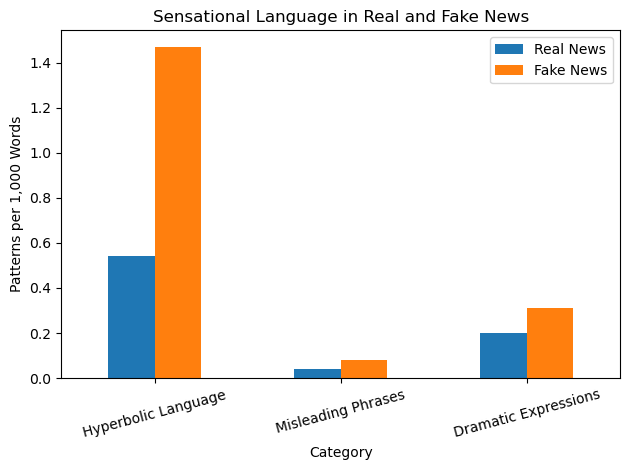

In [ ]:
# visualise the results
result.plot(x="Category",y=["Real News", "Fake News"],kind="bar")

plt.title("Sensational Language in Real and Fake News")
plt.ylabel("Patterns per 1,000 Words")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()